<a href="https://colab.research.google.com/github/madhav720/Probability_Research_paper/blob/main/Copy_of_Noise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Read Excel file
df = pd.read_csv("/content/Noise Data.csv")

# Display first few rows
#print(df.head())
print(df.head(10))


   ID_MEASURING_RECORD                    VOIVODESHIP         TOWN  \
0                    1  Lower Silesian (dolnoslaskie)  Boleslawiec   
1                    2  Lower Silesian (dolnoslaskie)  Boleslawiec   
2                    3  Lower Silesian (dolnoslaskie)  Boleslawiec   
3                    4  Lower Silesian (dolnoslaskie)  Boleslawiec   
4                    5  Lower Silesian (dolnoslaskie)  Boleslawiec   
5                    6  Lower Silesian (dolnoslaskie)  Boleslawiec   
6                    7  Lower Silesian (dolnoslaskie)  Boleslawiec   
7                    8  Lower Silesian (dolnoslaskie)  Boleslawiec   
8                    9  Lower Silesian (dolnoslaskie)  Boleslawiec   
9                   10  Lower Silesian (dolnoslaskie)  Boleslawiec   

  MEASURING_POINT_CODE  LATITUDE  LONGITUDE DATE_MEASUREMENT_START  \
0      D_02_000350_001   51.2558    15.5806       25-06-2018 11:53   
1      D_02_000350_001   51.2558    15.5806       17-10-2018 22:00   
2      D_02_000349_

Rows: 7386
Columns: 14
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7386 entries, 0 to 7385
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ID_MEASURING_RECORD       7386 non-null   int64  
 1   VOIVODESHIP               7386 non-null   object 
 2   TOWN                      6850 non-null   object 
 3   MEASURING_POINT_CODE      7386 non-null   object 
 4   LATITUDE                  7386 non-null   float64
 5   LONGITUDE                 7386 non-null   float64
 6   DATE_MEASUREMENT_START    7386 non-null   object 
 7   DATE_MEASUREMENT_END      7386 non-null   object 
 8   PERIOD_AND_TIME_SAMPLING  7386 non-null   object 
 9   AVG_NOISE_LVL             7386 non-null   float64
 10  MEU                       7386 non-null   int64  
 11  Duration_hours            7386 non-null   int64  
 12  Risk_Level                7386 non-null   object 
 13  Cumulative_MEU            7386 non-null 

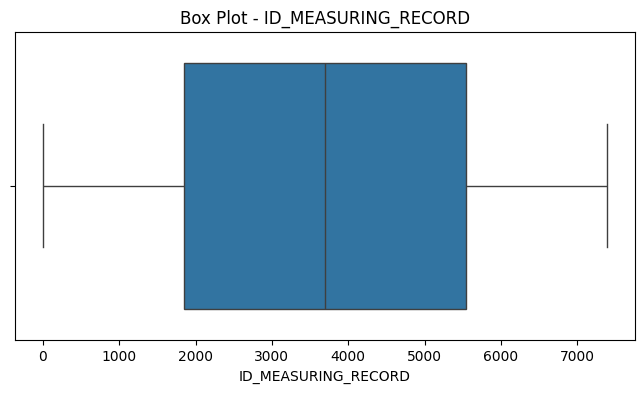

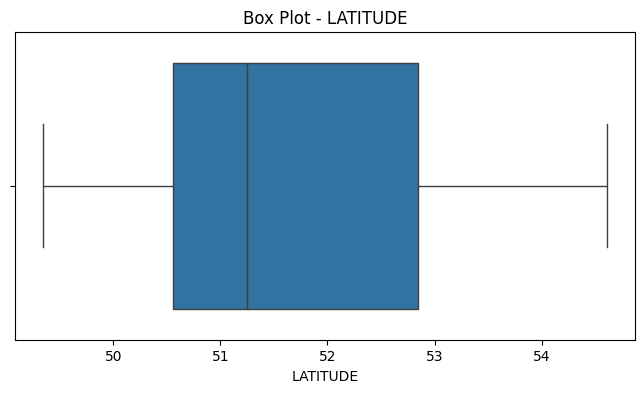

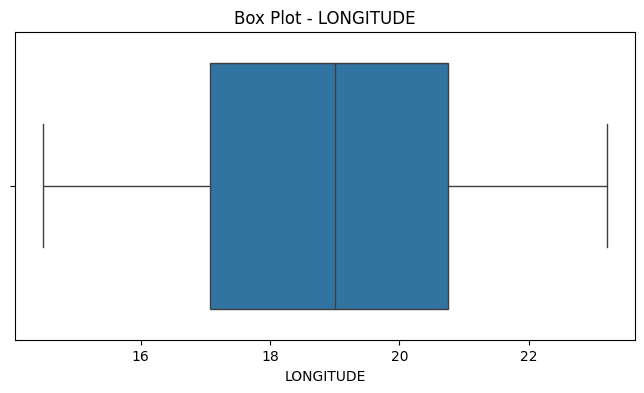

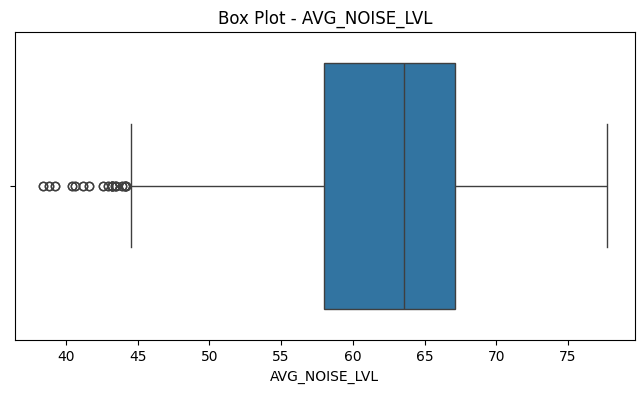

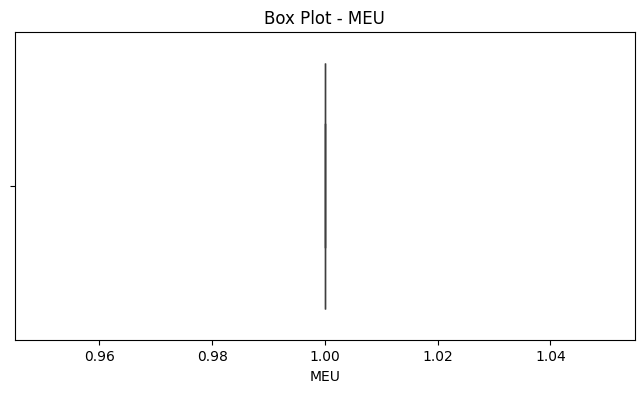

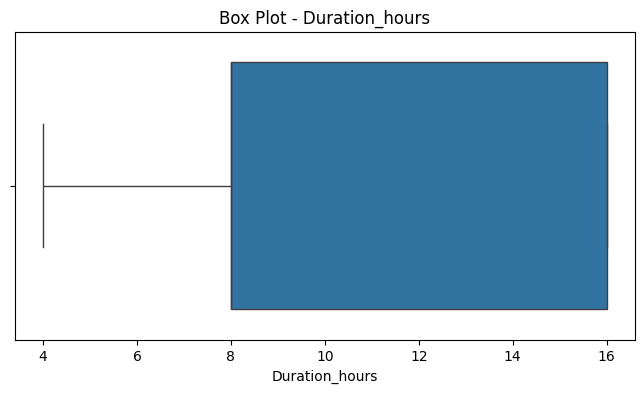

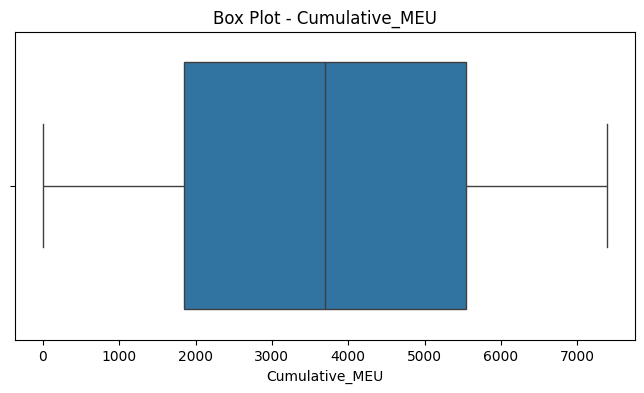

In [ ]:

# Dataset dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Column information
print(df.info())

# Descriptive statistics
print(df.describe(include='all'))

# Missing values
print("The number of missing values in this data",df.isnull().sum())

# Duplicate records
print("Duplicate rows:", df.duplicated().sum())

# Unique values
for col in df.columns:
    print(col, ":", df[col].nunique())

# Box plots
numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[col])
    plt.title(f"Box Plot - {col}")
    plt.show()




In [ ]:
from scipy.spatial import KDTree

# Separate data into known and unknown town locations
df_known = df.dropna(subset=['TOWN'])
df_unknown = df[df['TOWN'].isnull()]

# Create a KDTree for efficient nearest neighbor search on known town locations
# Using LATITUDE and LONGITUDE for proximity
known_locations = df_known[['LATITUDE', 'LONGITUDE']].values
known_towns = df_known['TOWN'].values
kdtree = KDTree(known_locations)

# Find the nearest known town for each unknown town location
if not df_unknown.empty:
    unknown_locations = df_unknown[['LATITUDE', 'LONGITUDE']].values
    distances, indices = kdtree.query(unknown_locations)

    # Impute missing 'TOWN' values with the town of the nearest neighbor
    imputed_towns = known_towns[indices]
    df.loc[df['TOWN'].isnull(), 'TOWN'] = imputed_towns

    print(f"Successfully imputed {len(df_unknown)} missing 'TOWN' values based on nearest neighbors.")
else:
    print("No missing 'TOWN' values to impute.")

# Verify that there are no more missing values in 'TOWN' column
print("\nMissing values after imputation:")
print(df.isnull().sum())

Successfully imputed 536 missing 'TOWN' values based on nearest neighbors.

Missing values after imputation:
ID_MEASURING_RECORD         0
VOIVODESHIP                 0
TOWN                        0
MEASURING_POINT_CODE        0
LATITUDE                    0
LONGITUDE                   0
DATE_MEASUREMENT_START      0
DATE_MEASUREMENT_END        0
PERIOD_AND_TIME_SAMPLING    0
AVG_NOISE_LVL               0
MEU                         0
Duration_hours              0
Risk_Level                  0
Cumulative_MEU              0
dtype: int64


In [ ]:
# Save the updated DataFrame to a new CSV file
df.to_csv('/content/Noise_Data_Imputed.csv', index=False)
print("DataFrame saved to /content/Noise_Data_Imputed.csv")
print(df.tail())

NameError: name 'df' is not defined

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Read Excel file
df = pd.read_csv("/content/Noise_Data_Imputed.csv")

# Dataset dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])


Rows: 7386
Columns: 14


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7386 entries, 0 to 7385
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ID_MEASURING_RECORD       7386 non-null   int64  
 1   VOIVODESHIP               7386 non-null   object 
 2   TOWN                      7386 non-null   object 
 3   MEASURING_POINT_CODE      7386 non-null   object 
 4   LATITUDE                  7386 non-null   float64
 5   LONGITUDE                 7386 non-null   float64
 6   DATE_MEASUREMENT_START    7386 non-null   object 
 7   DATE_MEASUREMENT_END      7386 non-null   object 
 8   PERIOD_AND_TIME_SAMPLING  7386 non-null   object 
 9   AVG_NOISE_LVL             7386 non-null   float64
 10  MEU                       7386 non-null   int64  
 11  Duration_hours            7386 non-null   int64  
 12  Risk_Level                7386 non-null   object 
 13  Cumulative_MEU            7386 non-null   int64  
dtypes: float

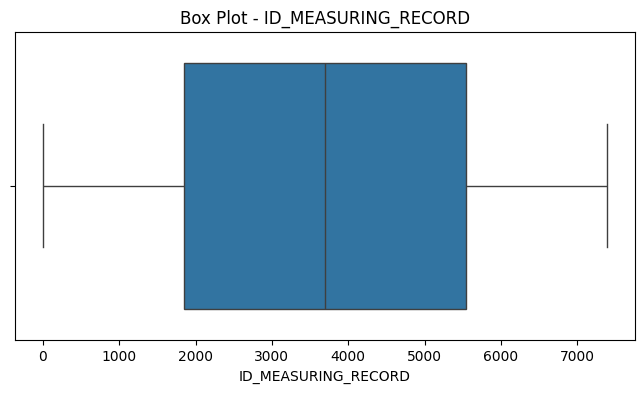

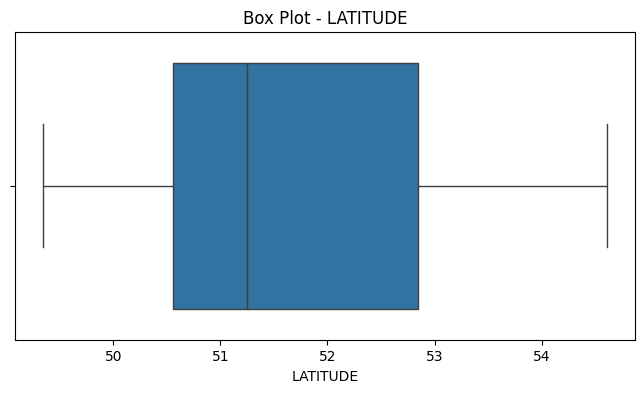

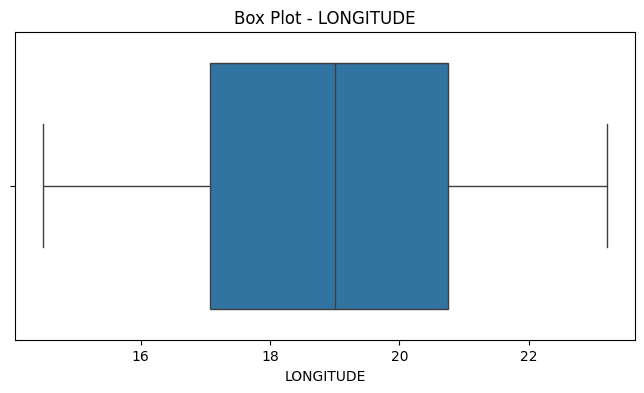

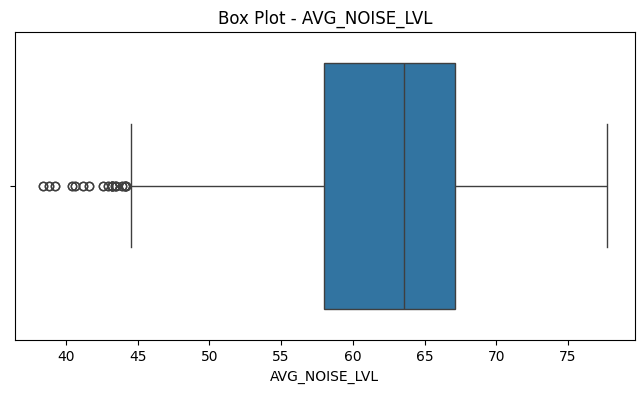

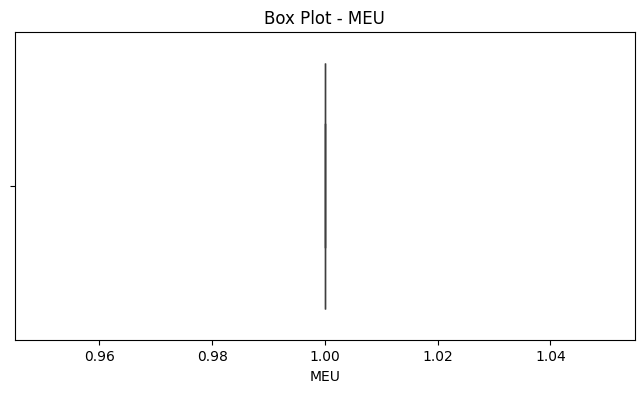

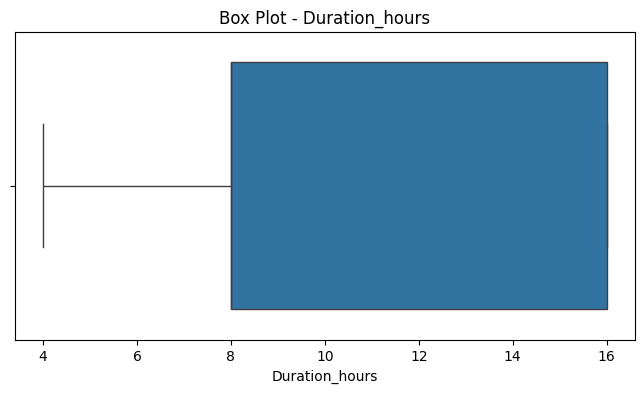

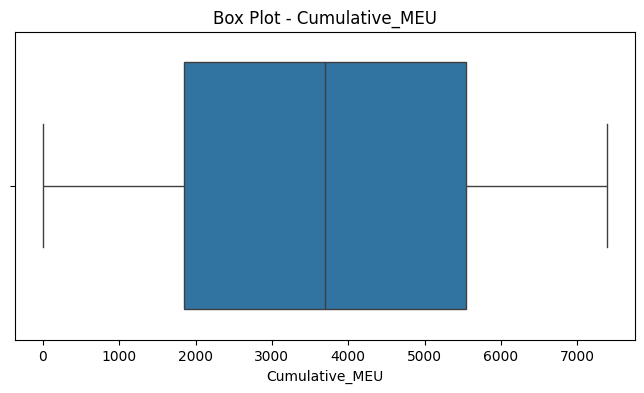

In [ ]:



# Column information
print(df.info())

# Descriptive statistics
print(df.describe(include='all'))

# Missing values
print("The number of missing values in this data",df.isnull().sum())

# Duplicate records
print("Duplicate rows:", df.duplicated().sum())

# Unique values
for col in df.columns:
    print(col, ":", df[col].nunique())

# Box plots
numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[col])
    plt.title(f"Box Plot - {col}")
    plt.show()




### Outlier Removal using IQR for `AVG_NOISE_LVL`

In [ ]:
# Calculate Q1, Q3, and IQR for 'AVG_NOISE_LVL'
Q1 = df['AVG_NOISE_LVL'].quantile(0.25)
Q3 = df['AVG_NOISE_LVL'].quantile(0.75)
IQR = Q3 - Q1

# Define outlier bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Q1 (AVG_NOISE_LVL): {Q1:.2f}")
print(f"Q3 (AVG_NOISE_LVL): {Q3:.2f}")
print(f"IQR (AVG_NOISE_LVL): {IQR:.2f}")
print(f"Lower Bound (AVG_NOISE_LVL): {lower_bound:.2f}")
print(f"Upper Bound (AVG_NOISE_LVL): {upper_bound:.2f}")

# Identify outliers
outliers = df[(df['AVG_NOISE_LVL'] < lower_bound) | (df['AVG_NOISE_LVL'] > upper_bound)]
print(f"\nNumber of outliers identified: {len(outliers)}")

# Store the original number of records
original_records = len(df)

# Remove outliers
df_cleaned = df[~((df['AVG_NOISE_LVL'] < lower_bound) | (df['AVG_NOISE_LVL'] > upper_bound))]

# Display the shape before and after removal
print(f"\nNumber of records before outlier removal: {original_records}")
print(f"Number of records after outlier removal: {len(df_cleaned)}")
print(f"Number of records removed: {original_records - len(df_cleaned)}")


Q1 (AVG_NOISE_LVL): 58.00
Q3 (AVG_NOISE_LVL): 67.10
IQR (AVG_NOISE_LVL): 9.10
Lower Bound (AVG_NOISE_LVL): 44.35
Upper Bound (AVG_NOISE_LVL): 80.75

Number of outliers identified: 36

Number of records before outlier removal: 7386
Number of records after outlier removal: 7350
Number of records removed: 36


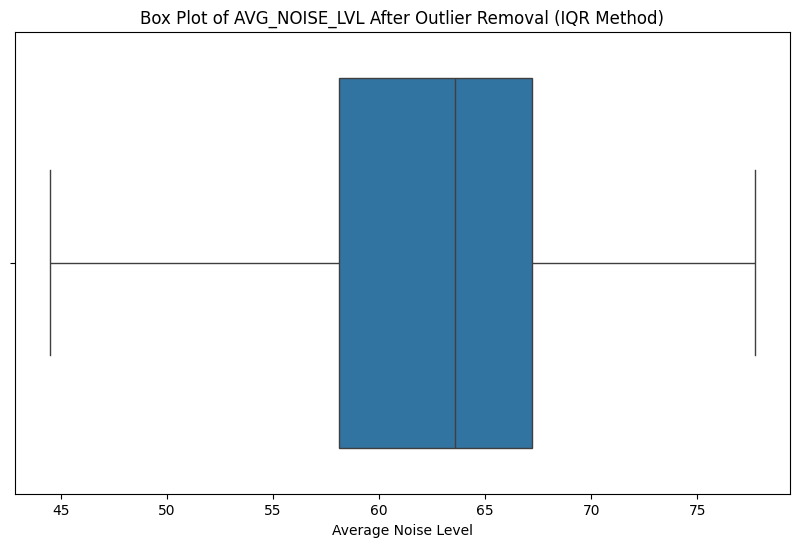

DataFrame 'df' has been updated with outliers removed.


In [ ]:
# Display a box plot of 'AVG_NOISE_LVL' after outlier removal
plt.figure(figsize=(10, 6))
sns.boxplot(x=df_cleaned['AVG_NOISE_LVL'])
plt.title('Box Plot of AVG_NOISE_LVL After Outlier Removal (IQR Method)')
plt.xlabel('Average Noise Level')
plt.show()

# Update the main DataFrame 'df' to reflect the cleaned data
df = df_cleaned.copy()
print("DataFrame 'df' has been updated with outliers removed.")

/tmp/ipykernel_1917/420237234.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='AVG_NOISE_LVL', y='VOIVODESHIP', data=avg_noise_by_voivodeship, palette='viridis')


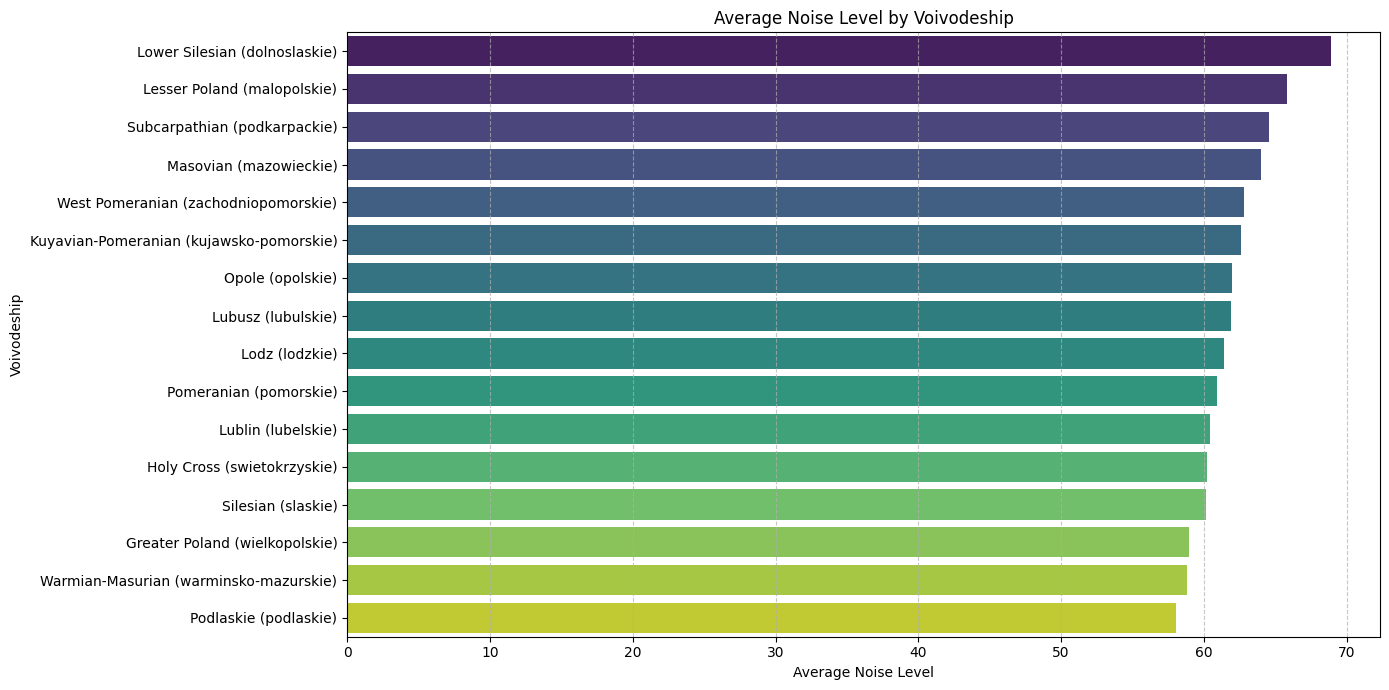


--- Interpreting the Bar Plot ---
Magnitude: The length of each bar directly represents the average noise level for that voivodeship. Longer bars indicate higher average noise.
Ranking: The bars are sorted in descending order of average noise level, making it easy to see which voivodeships have the highest and lowest average noise levels.
Changes over categories: By observing the differences in bar lengths from top to bottom, you can easily spot the relative changes in average noise levels between different voivodeships.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the average AVG_NOISE_LVL for each VOIVODESHIP
avg_noise_by_voivodeship = df.groupby('VOIVODESHIP')['AVG_NOISE_LVL'].mean().sort_values(ascending=False).reset_index()

plt.figure(figsize=(14, 7))
sns.barplot(x='AVG_NOISE_LVL', y='VOIVODESHIP', data=avg_noise_by_voivodeship, palette='viridis')
plt.title('Average Noise Level by Voivodeship')
plt.xlabel('Average Noise Level')
plt.ylabel('Voivodeship')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

print("\n--- Interpreting the Bar Plot ---")
print("Magnitude: The length of each bar directly represents the average noise level for that voivodeship. Longer bars indicate higher average noise.")
print("Ranking: The bars are sorted in descending order of average noise level, making it easy to see which voivodeships have the highest and lowest average noise levels.")
print("Changes over categories: By observing the differences in bar lengths from top to bottom, you can easily spot the relative changes in average noise levels between different voivodeships.")

/tmp/ipykernel_1917/1836749679.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='AVG_NOISE_LVL', y='TOWN', data=avg_noise_by_town, palette='viridis')


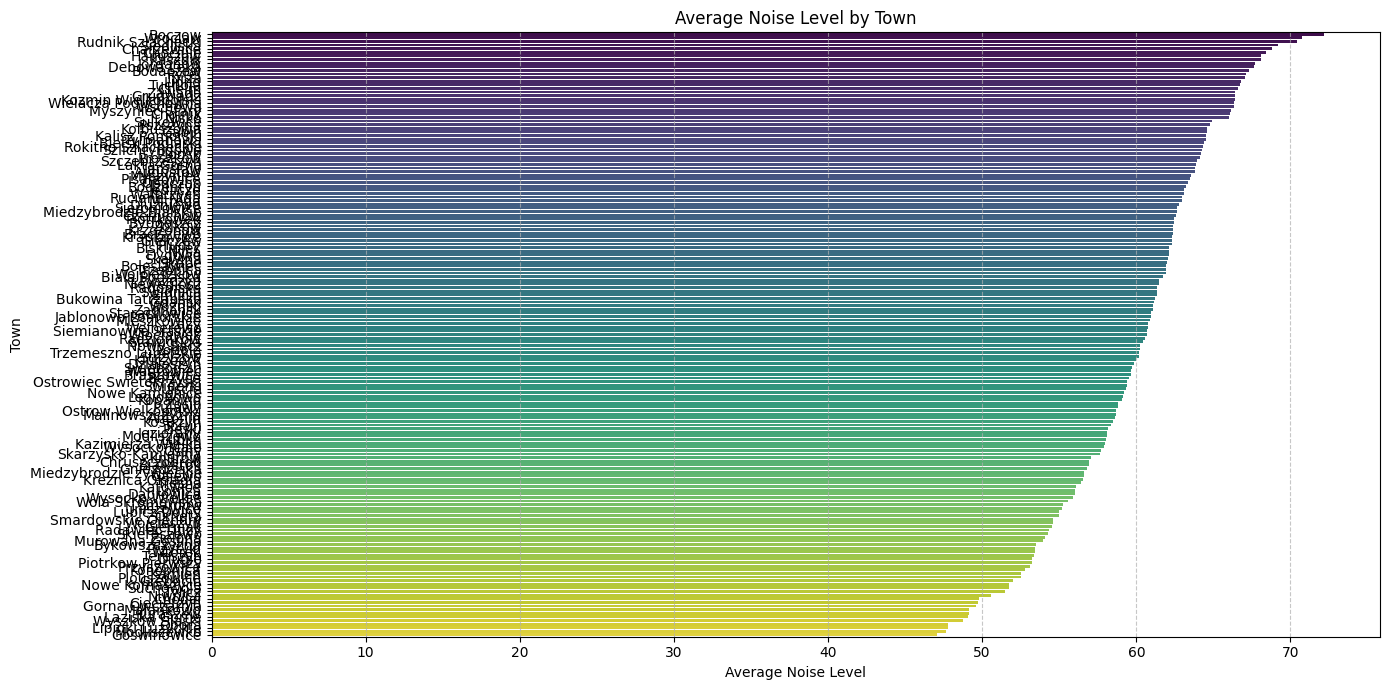


--- Interpreting the Bar Plot ---
Magnitude: The length of each bar directly represents the average noise level for that town. Longer bars indicate higher average noise.
Ranking: The bars are sorted in descending order of average noise level, making it easy to see which towns have the highest and lowest average noise levels.
Changes over categories: By observing the differences in bar lengths from top to bottom, you can easily spot the relative changes in average noise levels between different towns.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the average AVG_NOISE_LVL for each TOWN
avg_noise_by_town = df.groupby('TOWN')['AVG_NOISE_LVL'].mean().sort_values(ascending=False).reset_index()

plt.figure(figsize=(14, 7))
sns.barplot(x='AVG_NOISE_LVL', y='TOWN', data=avg_noise_by_town, palette='viridis')
plt.title('Average Noise Level by Town')
plt.xlabel('Average Noise Level')
plt.ylabel('Town')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

print("\n--- Interpreting the Bar Plot ---")
print("Magnitude: The length of each bar directly represents the average noise level for that town. Longer bars indicate higher average noise.")
print("Ranking: The bars are sorted in descending order of average noise level, making it easy to see which towns have the highest and lowest average noise levels.")
print("Changes over categories: By observing the differences in bar lengths from top to bottom, you can easily spot the relative changes in average noise levels between different towns.")

/tmp/ipykernel_1917/1945493692.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Risk_Score', y='TOWN', data=avg_risk_by_town, palette='viridis')


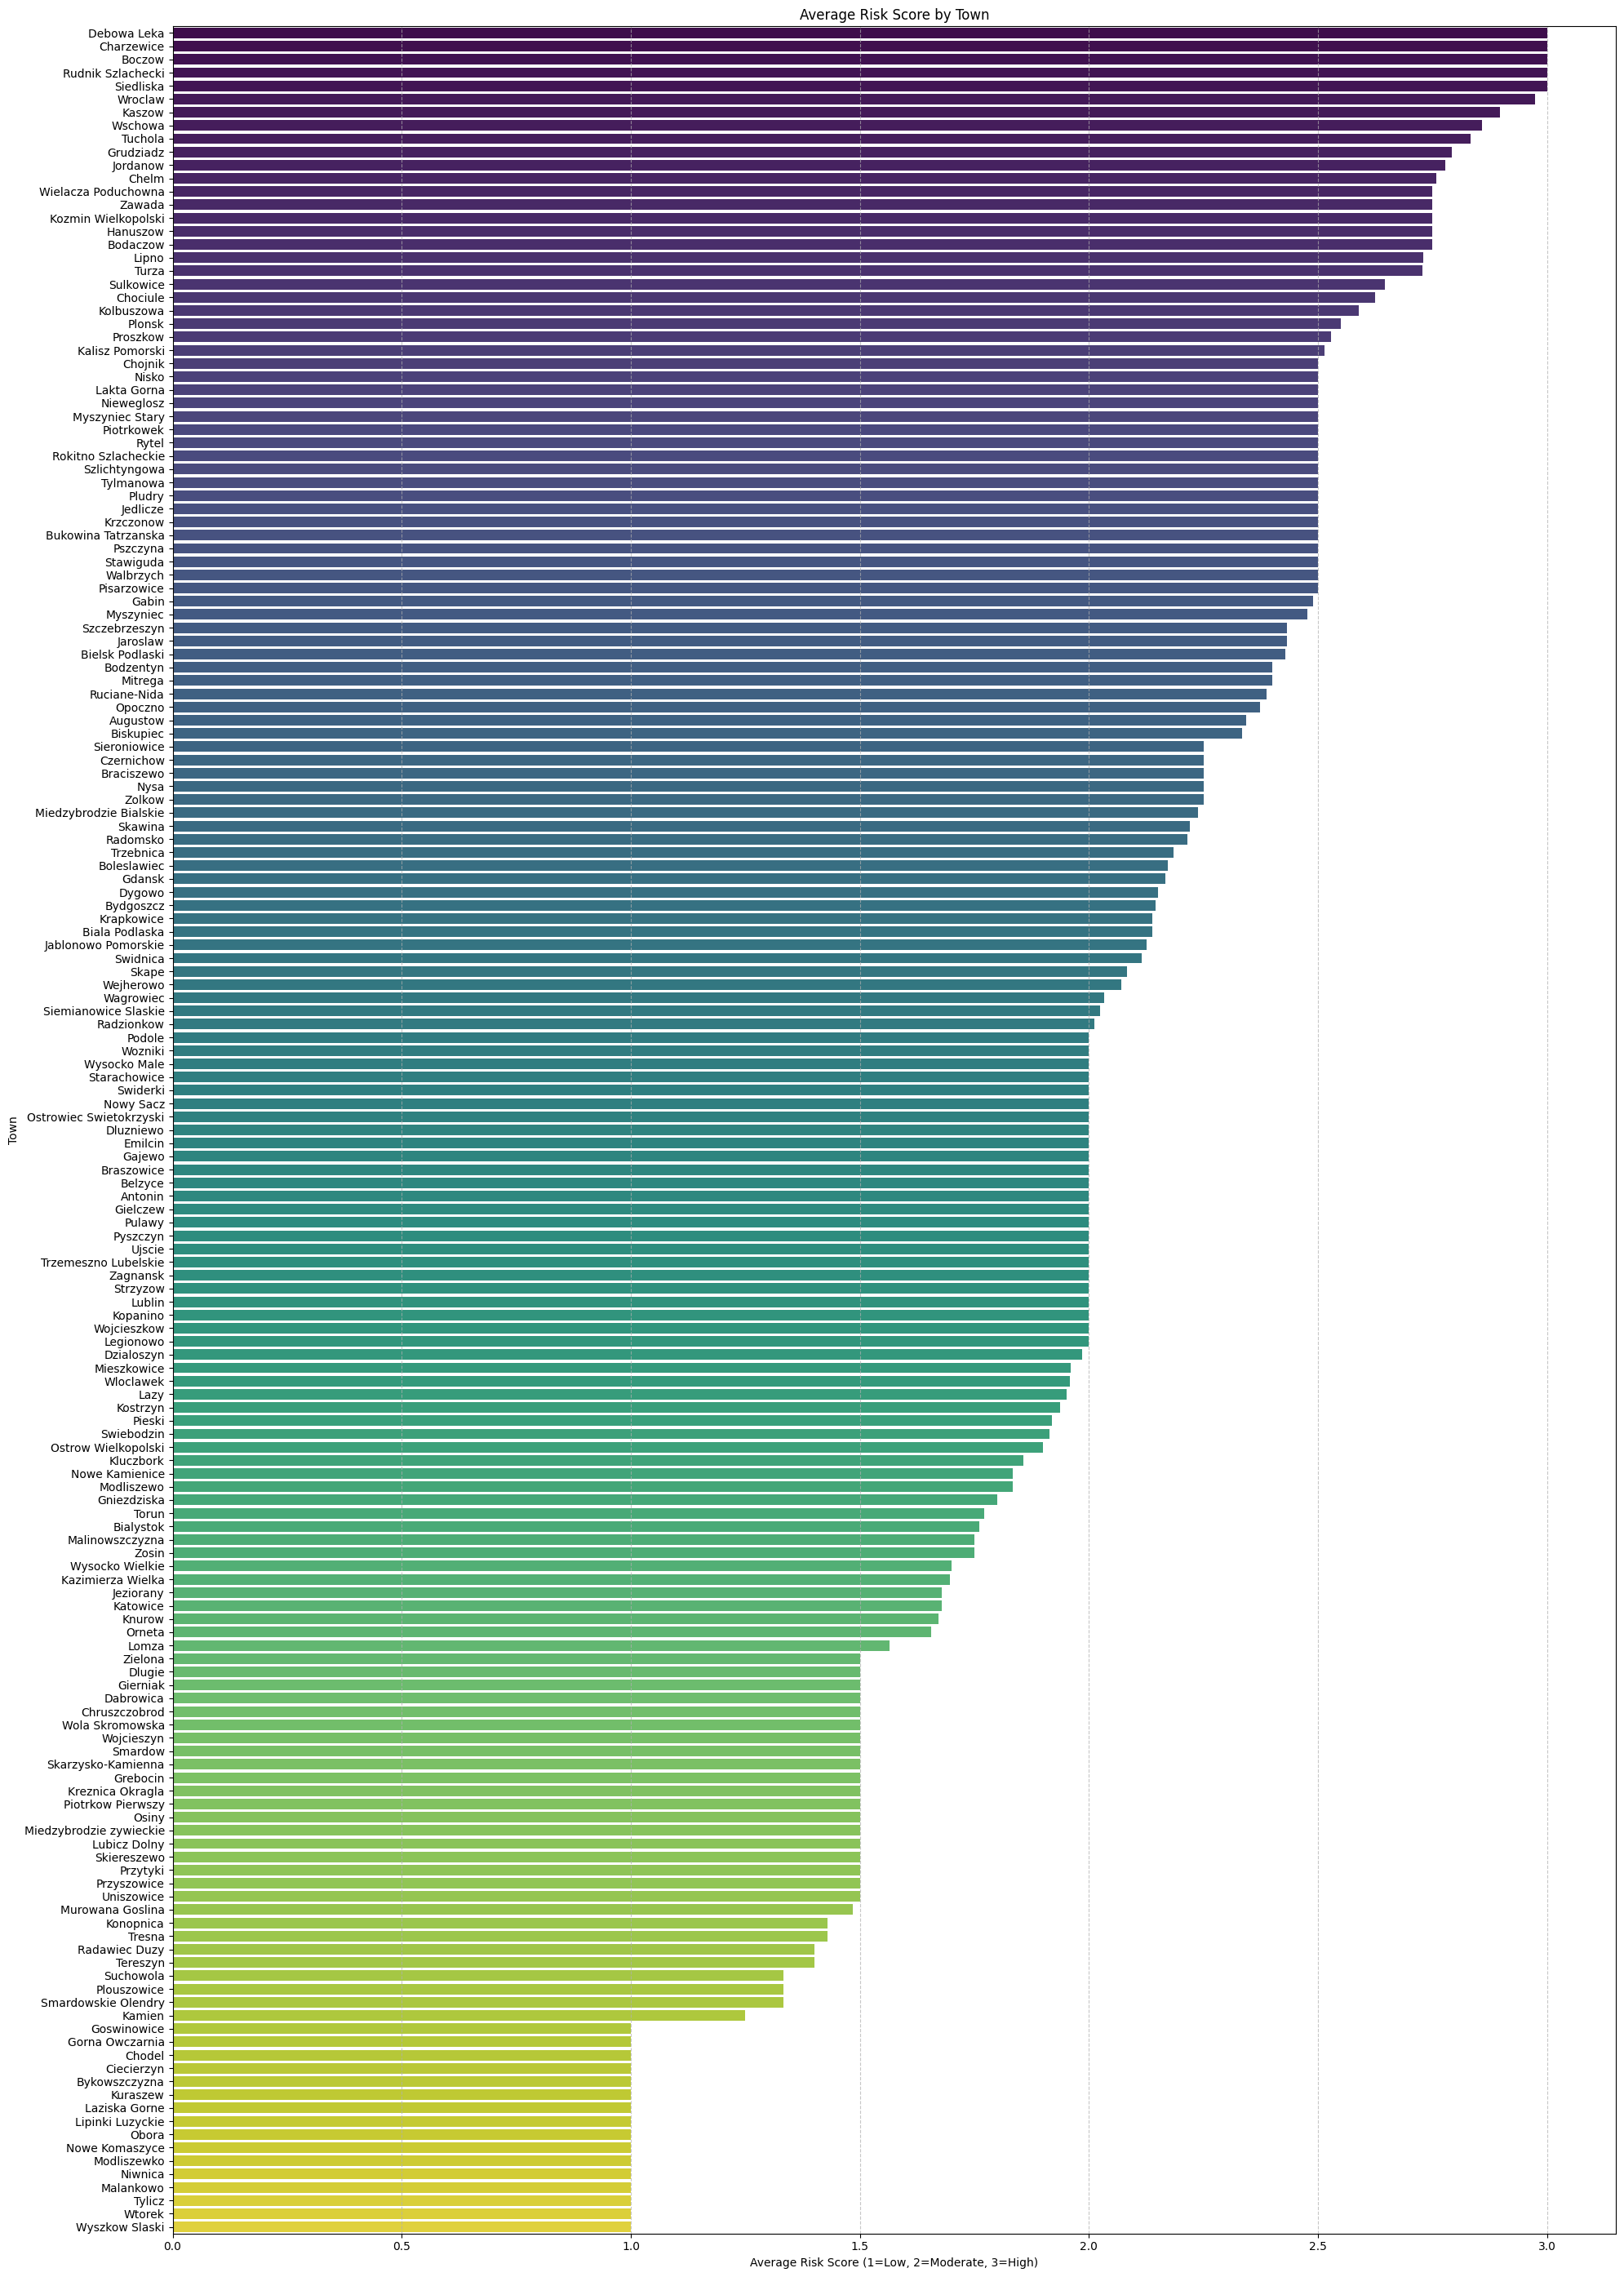


--- Interpreting the Bar Plot ---
Magnitude: The length of each bar directly represents the average risk score for that town. Longer bars indicate a higher average risk.
Ranking: The bars are sorted in descending order of average risk score, making it easy to see which towns have the highest and lowest average risk scores.
Changes over categories: By observing the differences in bar lengths from top to bottom, you can easily spot the relative changes in average risk scores between different towns.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Map 'Risk_Level' categories to numerical values
risk_mapping = {'Low': 1, 'Moderate': 2, 'High': 3}
df['Risk_Score'] = df['Risk_Level'].map(risk_mapping)

# Calculate the average Risk_Score for each TOWN
avg_risk_by_town = df.groupby('TOWN')['Risk_Score'].mean().sort_values(ascending=False).reset_index()

plt.figure(figsize=(20, 28))
sns.barplot(x='Risk_Score', y='TOWN', data=avg_risk_by_town, palette='viridis')
plt.title('Average Risk Score by Town')
plt.xlabel('Average Risk Score (1=Low, 2=Moderate, 3=High)')
plt.ylabel('Town')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

print("\n--- Interpreting the Bar Plot ---")
print("Magnitude: The length of each bar directly represents the average risk score for that town. Longer bars indicate a higher average risk.")
print("Ranking: The bars are sorted in descending order of average risk score, making it easy to see which towns have the highest and lowest average risk scores.")
print("Changes over categories: By observing the differences in bar lengths from top to bottom, you can easily spot the relative changes in average risk scores between different towns.")

In [ ]:
print(df.groupby('Risk_Level')['Duration_hours'].describe())

             count       mean       std  min  25%   50%   75%   max
Risk_Level                                                         
High        2910.0  11.106529  4.564988  4.0  8.0  12.0  16.0  16.0
Low          952.0   9.903361  3.488770  4.0  8.0   8.0  12.0  16.0
Moderate    3488.0   9.965596  4.327696  4.0  8.0   8.0  16.0  16.0


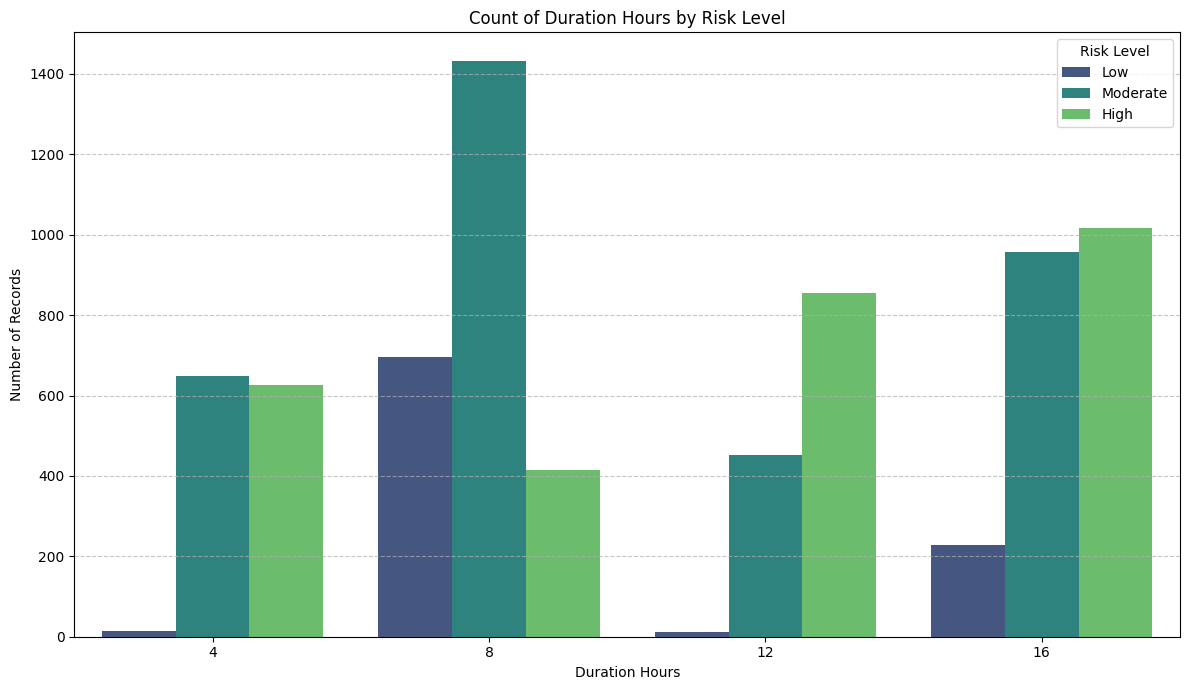

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count the occurrences of each Duration_hours for each Risk_Level
risk_duration_counts = df.groupby(['Risk_Level', 'Duration_hours']).size().reset_index(name='Count')

plt.figure(figsize=(12, 7))
sns.barplot(x='Duration_hours', y='Count', hue='Risk_Level', data=risk_duration_counts,
            order=sorted(df['Duration_hours'].unique()), # Ensure correct numerical order for x-axis
            hue_order=['Low', 'Moderate', 'High'], # Ensure consistent order for risk levels
            palette='viridis')

plt.title('Count of Duration Hours by Risk Level')
plt.xlabel('Duration Hours')
plt.ylabel('Number of Records')
plt.legend(title='Risk Level')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


/tmp/ipykernel_1917/2175762945.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Risk_Level', y='AVG_NOISE_LVL', data=avg_noise_by_risk,


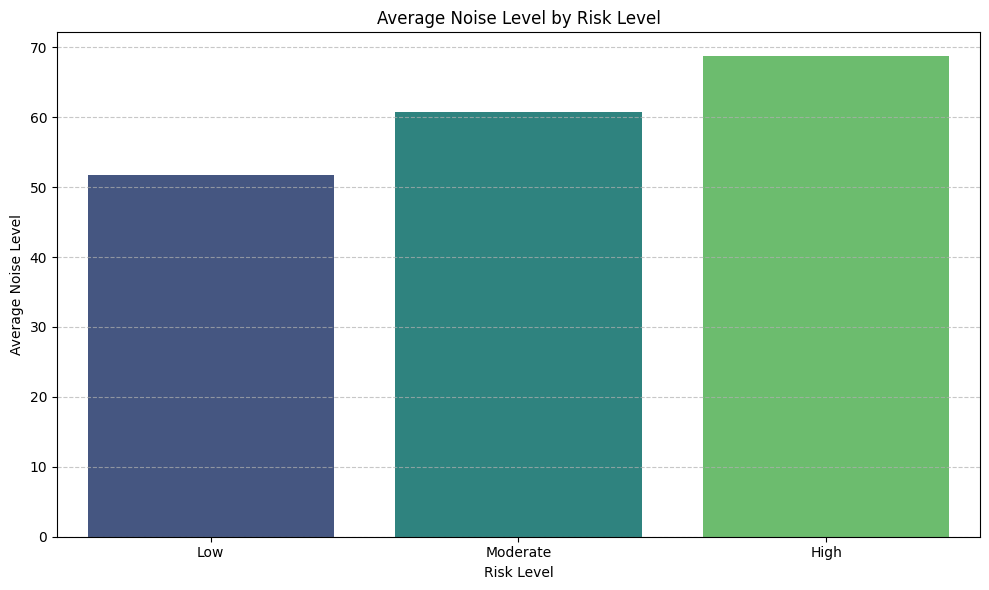

In [ ]:
# Calculate the average AVG_NOISE_LVL for each Risk_Level
avg_noise_by_risk = df.groupby('Risk_Level')['AVG_NOISE_LVL'].mean().reindex(['Low', 'Moderate', 'High']).reset_index()

plt.figure(figsize=(10, 6))
sns.barplot(x='Risk_Level', y='AVG_NOISE_LVL', data=avg_noise_by_risk,
            order=['Low', 'Moderate', 'High'], # Explicitly set order for consistency
            palette='viridis')

plt.title('Average Noise Level by Risk Level')
plt.xlabel('Risk Level')
plt.ylabel('Average Noise Level')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Interpretation of the Bar Chart:

This bar chart directly compares the average `AVG_NOISE_LVL` for each `Risk_Level`.

*   The height of each bar represents the average noise level for that particular risk category.
*   This allows us to quickly see if there's a clear difference in the typical noise levels associated with 'Low', 'Moderate', and 'High' risks.

For example, if the 'High' risk bar is significantly taller than the 'Low' risk bar, it would indicate that high-risk measurements generally have higher average noise levels.

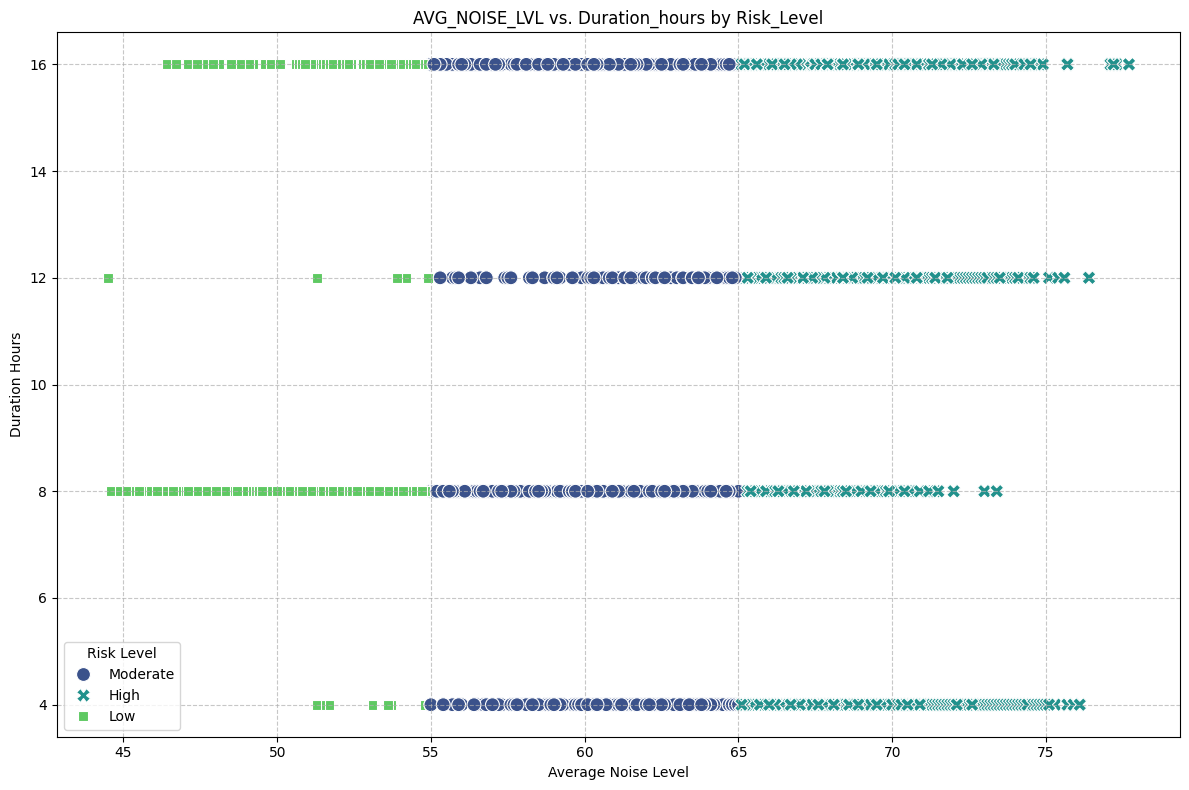

In [ ]:
plt.figure(figsize=(12, 8))
sns.scatterplot(x='AVG_NOISE_LVL', y='Duration_hours', hue='Risk_Level', data=df,
                palette='viridis', style='Risk_Level', s=100) # s=100 for larger points

plt.title('AVG_NOISE_LVL vs. Duration_hours by Risk_Level')
plt.xlabel('Average Noise Level')
plt.ylabel('Duration Hours')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(title='Risk Level')
plt.tight_layout()
plt.show()

### Interpretation of the Three-Variable Scatter Plot:

This scatter plot helps us visualize how `AVG_NOISE_LVL` and `Duration_hours` interact, with the added dimension of `Risk_Level` (represented by color and style).

*   **Clusters/Separation**: Look for any distinct groupings of points based on color. Do 'Low', 'Moderate', and 'High' risk levels tend to occupy different regions of the plot?
*   **Trends within Risk Levels**: Within each color group, observe if there's any correlation between `AVG_NOISE_LVL` and `Duration_hours`. For instance, do higher `AVG_NOISE_LVL` values within the 'High' risk category also correspond to longer `Duration_hours`?
*   **Overlap**: Note areas where different `Risk_Level`s overlap significantly. This would suggest that `AVG_NOISE_LVL` and `Duration_hours` alone might not be sufficient to perfectly distinguish between those risk levels.

This visualization provides a more holistic view of the interdependencies between these three important variables.

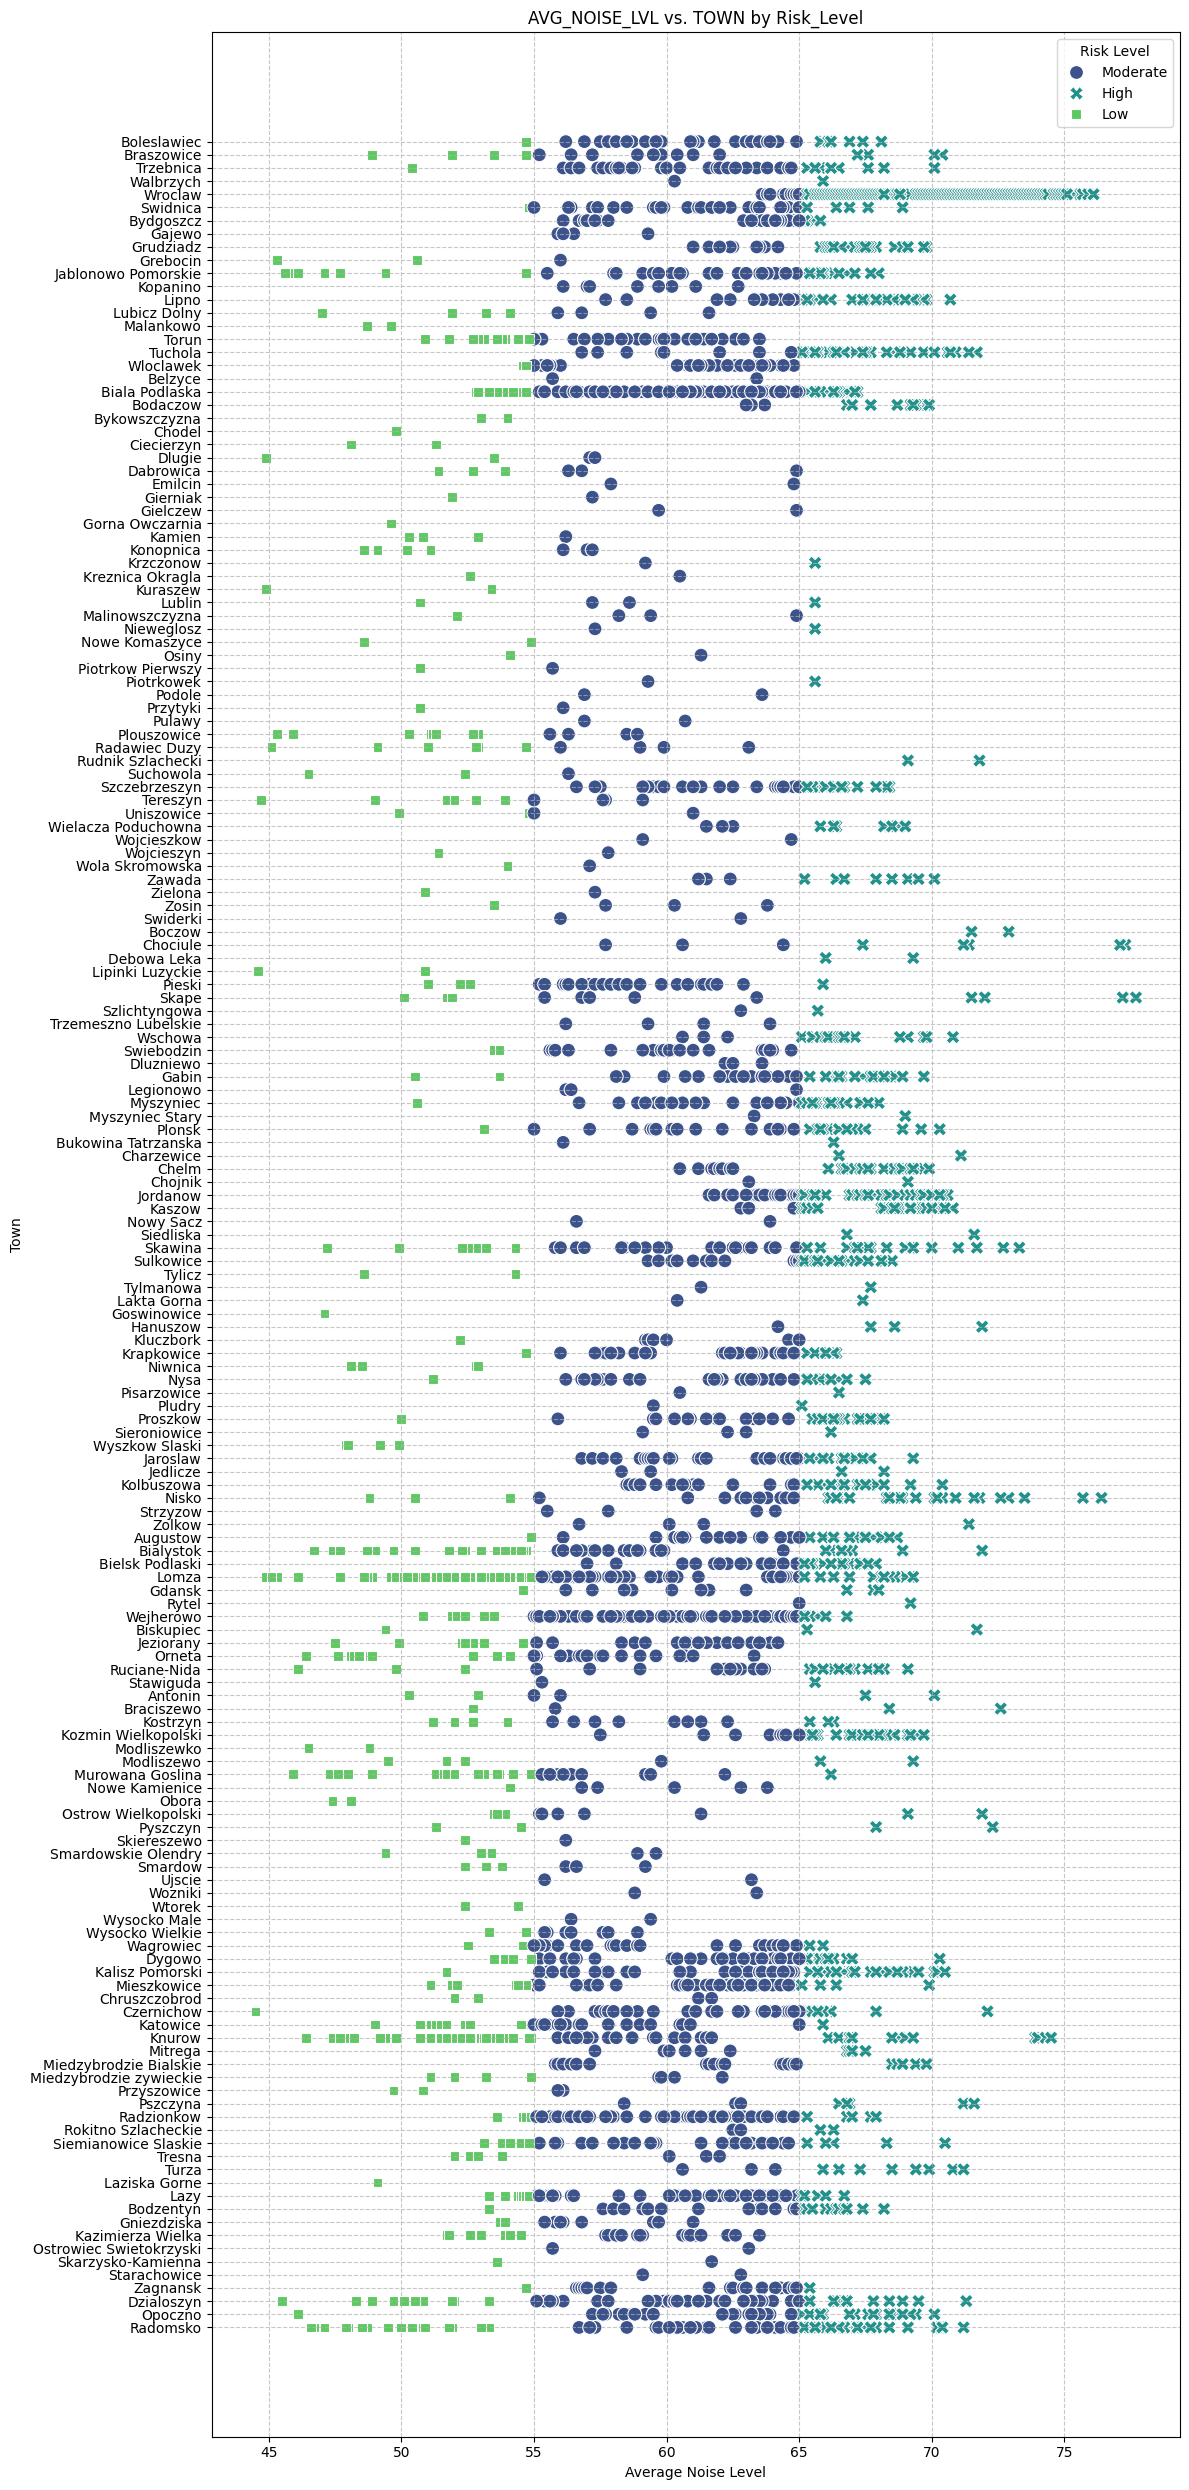

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 25)) # Increased height for better visibility of town labels
sns.scatterplot(x='AVG_NOISE_LVL', y='TOWN', hue='Risk_Level', data=df,
                palette='viridis', style='Risk_Level', s=100) # s=100 for larger points

plt.title('AVG_NOISE_LVL vs. TOWN by Risk_Level')
plt.xlabel('Average Noise Level')
plt.ylabel('Town')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(title='Risk Level')
plt.tight_layout()
plt.show()

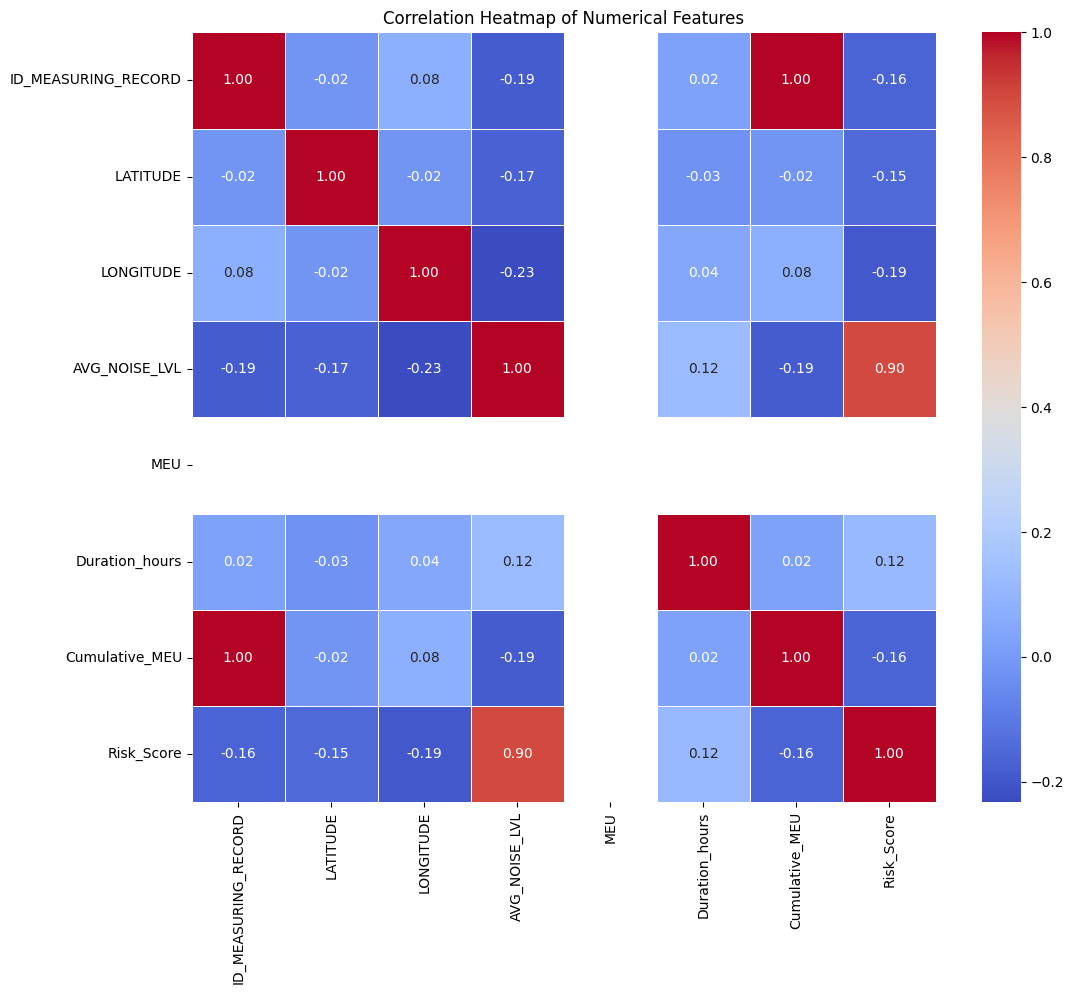

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select only numerical columns for correlation calculation
numerical_df = df.select_dtypes(include=['number'])

# Calculate the correlation matrix
correlation_matrix = numerical_df.corr()

# Create a heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

### Violin Plot: `AVG_NOISE_LVL` by `Risk_Level`

A violin plot is useful for visualizing the distribution of a numerical variable across different categories. It shows the probability density of the data at different values, much like a smoothed histogram, along with a box plot inside.

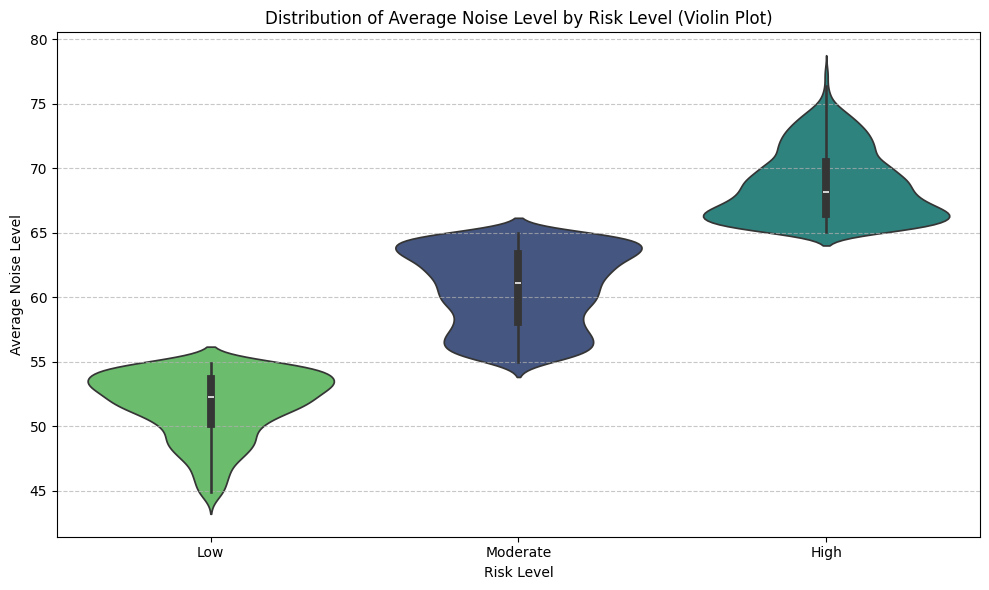

In [ ]:
plt.figure(figsize=(10, 6))
sns.violinplot(x='Risk_Level', y='AVG_NOISE_LVL', data=df, order=['Low', 'Moderate', 'High'], palette='viridis', hue='Risk_Level', legend=False)
plt.title('Distribution of Average Noise Level by Risk Level (Violin Plot)')
plt.xlabel('Risk Level')
plt.ylabel('Average Noise Level')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Interpretation of the Violin Plot:

*   **Shape**: The width of the 'violin' at any given point indicates the density of observations at that value. A wider section means more data points are concentrated there.
*   **Internal Box Plot**: Inside each violin, there is a miniature box plot showing the median (white dot), interquartile range (thick bar), and whiskers (thin lines).
*   **Comparison**: This plot allows for a quick visual comparison of the distributions of `AVG_NOISE_LVL` for 'Low', 'Moderate', and 'High' risk levels. You can observe differences in the spread, skewness, and central tendency of noise levels across these categories.

### Violin Plot: `Duration_hours` by `Risk_Level`

This violin plot visualizes the distribution of `Duration_hours` for each `Risk_Level` category. It allows us to see not just the central tendency but also the spread and density of `Duration_hours` within each risk level.

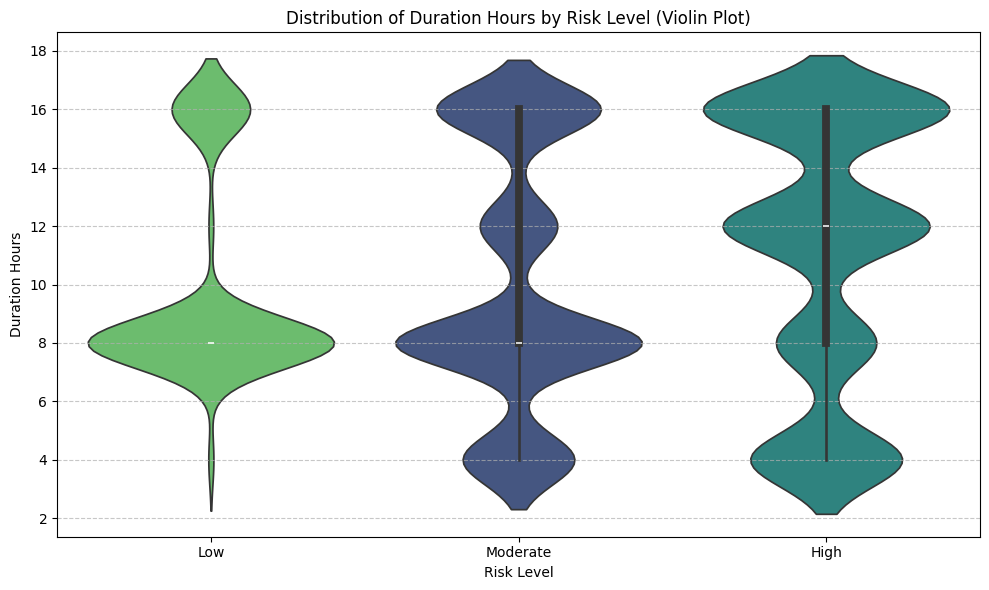

In [ ]:
plt.figure(figsize=(10, 6))
sns.violinplot(x='Risk_Level', y='Duration_hours', data=df, order=['Low', 'Moderate', 'High'], palette='viridis', hue='Risk_Level', legend=False)
plt.title('Distribution of Duration Hours by Risk Level (Violin Plot)')
plt.xlabel('Risk Level')
plt.ylabel('Duration Hours')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Interpretation of the Violin Plot (Duration_hours by Risk_Level):

*   **Distribution Shape**: Observe the shape of each violin. For example, a wider section at 8 hours for 'Low' risk would indicate a high concentration of measurements with 8-hour durations in that risk category.
*   **Median and Quartiles**: The internal box plot shows the median (white dot) and the interquartile range (thick bar), providing insights into the typical duration hours for each risk level.
*   **Outliers**: The whiskers extending from the box plot show the range of the data, and individual points beyond the whiskers would represent outliers.
*   **Comparison**: This plot helps in comparing whether higher risk levels are generally associated with longer or more varied `Duration_hours`.

## Building a Logistic Regression Model

We will now build a logistic regression model to predict `Risk_Level` based on `TOWN`, `Duration_hours`, and `AVG_NOISE_LVL`. Since `Risk_Level` is an ordinal categorical variable (Low, Moderate, High), we will use a multinomial logistic regression approach.

**Steps involved:**
1.  **Feature and Target Selection**: Define the predictor variables (features) and the target variable.
2.  **Categorical Feature Encoding**: Convert categorical variables (`TOWN`) into a numerical format suitable for the model using one-hot encoding.
3.  **Data Splitting**: Divide the dataset into training and testing sets.
4.  **Feature Scaling**: Scale numerical features to ensure that no single feature dominates the model due to its scale.
5.  **Model Training**: Train a Logistic Regression model.
6.  **Model Evaluation**: Assess the model's performance using appropriate metrics.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Define features (X) and target (y)
# Including 'TOWN' as a categorical feature and 'LATITUDE', 'LONGITUDE' as numerical features
X = df[['TOWN', 'LATITUDE', 'LONGITUDE', 'Duration_hours', 'AVG_NOISE_LVL']]
y = df['Risk_Score'] # Using the numerical Risk_Score (1, 2, 3)

### Data Preprocessing: Encoding and Scaling

We'll use a `ColumnTransformer` to apply different preprocessing steps to different columns:
*   **One-Hot Encoding** for `TOWN` (categorical feature).
*   **Standard Scaling** for `Duration_hours` and `AVG_NOISE_LVL` (numerical features).

In [ ]:
# Identify categorical and numerical features
categorical_features = ['TOWN']
numerical_features = ['LATITUDE', 'LONGITUDE', 'Duration_hours', 'AVG_NOISE_LVL']

# Create preprocessing pipelines for numerical and categorical features
numerical_transformer = StandardScaler()
categorical_transformer = OneHotEncoder(handle_unknown='ignore') # 'ignore' handles categories not seen during training

# Create a column transformer to apply different transformations
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ])

### Splitting Data into Training and Testing Sets

We'll split the data into 80% for training and 20% for testing to evaluate the model's generalization performance.

In [ ]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42, stratify=y)

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Test set size: {X_test.shape[0]} samples")

Training set size: 4410 samples
Test set size: 2940 samples


### Training the Multinomial Logistic Regression Model

We'll build a `Pipeline` that first applies the preprocessing steps and then trains the `LogisticRegression` model. We specify `multi_class='multinomial'` for our ordinal target variable and choose a suitable solver.

In [ ]:
# Create the logistic regression model pipeline
model = Pipeline(steps=[('preprocessor', preprocessor),
                        ('classifier', LogisticRegression(multi_class='multinomial', solver='lbfgs', random_state=42, max_iter=1000))])

# Train the model
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_proba = model.predict_proba(X_test)

print("Predicted Probabilities (first 5 samples):\n", y_pred_proba[:5])

print("Model training complete!")


Predicted Probabilities (first 5 samples):
 [[2.70133209e-05 9.99928805e-01 4.41821412e-05]
 [2.01301144e-15 4.57248606e-05 9.99954275e-01]
 [3.28466966e-17 4.03759067e-06 9.99995962e-01]
 [6.49925094e-06 9.99018788e-01 9.74712915e-04]
 [8.95390984e-08 8.09314638e-01 1.90685272e-01]]
Model training complete!


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


In [ ]:
s=sum(y_pred_proba[0])
print(s)


1.0


### Model Evaluation and "Is it worthy?" Discussion

Let's evaluate the model's performance on the test set and discuss its worthiness.

Predicted Class Labels (first 5 samples):
 [2 3 3 2 2]

Predicted Probabilities (first 5 samples):
 [[2.70133209e-05 9.99928805e-01 4.41821412e-05]
 [2.01301144e-15 4.57248606e-05 9.99954275e-01]
 [3.28466966e-17 4.03759067e-06 9.99995962e-01]
 [6.49925094e-06 9.99018788e-01 9.74712915e-04]
 [8.95390984e-08 8.09314638e-01 1.90685272e-01]]

Model Accuracy: 0.9850

Classification Report:
              precision    recall  f1-score   support

           1       1.00      0.96      0.98       381
           2       0.98      0.99      0.98      1395
           3       0.99      0.98      0.99      1164

    accuracy                           0.99      2940
   macro avg       0.99      0.98      0.98      2940
weighted avg       0.99      0.99      0.99      2940



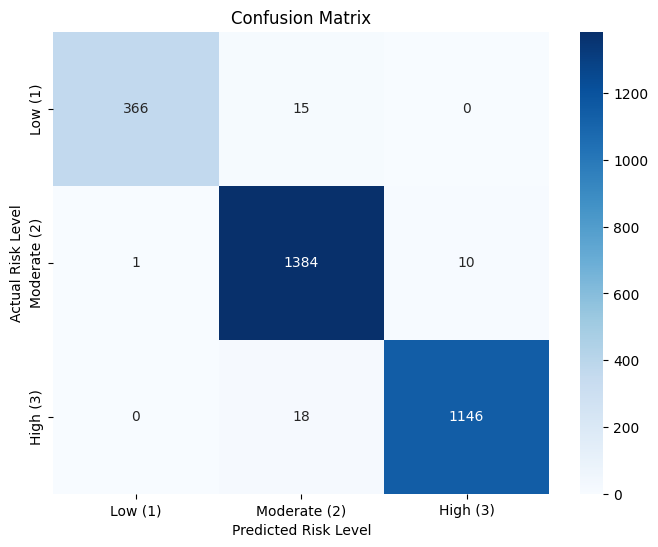

In [ ]:
# Make predictions on the test set
y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)

print("Predicted Class Labels (first 5 samples):\n", y_pred[:5])
print("\nPredicted Probabilities (first 5 samples):\n", y_pred_proba[:5])

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)
conf_mat = confusion_matrix(y_test, y_pred)

print(f"\nModel Accuracy: {accuracy:.4f}")
print("\nClassification Report:")
print(report)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Low (1)', 'Moderate (2)', 'High (3)'],
            yticklabels=['Low (1)', 'Moderate (2)', 'High (3)'])
plt.xlabel('Predicted Risk Level')
plt.ylabel('Actual Risk Level')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
# Install XGBoost and LightGBM if not already installed
!pip install xgboost lightgbm --quiet

## Random Forest Classifier

**When to use it:** Random Forest is an ensemble learning method that builds multiple decision trees and merges their predictions to get a more accurate and stable prediction. It's excellent for both classification and regression tasks, handles non-linear relationships well, is less prone to overfitting than single decision trees, and works well with a mix of numerical and categorical features. It also provides feature importance, which can be valuable for understanding the impact of different features on the prediction.

Here, we will use it to classify `Risk_Level`.


Random Forest Model Accuracy: 0.9986

Random Forest Classification Report:
              precision    recall  f1-score   support

           1       1.00      0.99      0.99       190
           2       1.00      1.00      1.00       698
           3       1.00      1.00      1.00       582

    accuracy                           1.00      1470
   macro avg       1.00      1.00      1.00      1470
weighted avg       1.00      1.00      1.00      1470



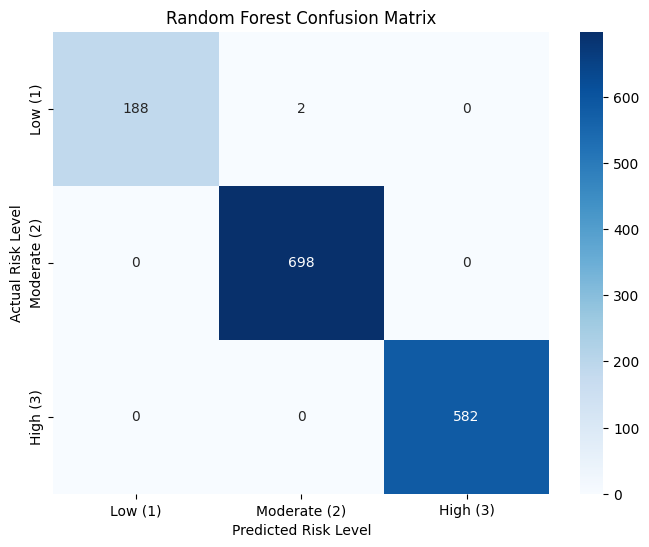

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model pipeline
rf_model = Pipeline(steps=[('preprocessor', preprocessor),
                           ('classifier', RandomForestClassifier(random_state=42))])

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_rf = rf_model.predict(X_test)

# Evaluate the model
accuracy_rf = accuracy_score(y_test, y_pred_rf)
report_rf = classification_report(y_test, y_pred_rf)
conf_mat_rf = confusion_matrix(y_test, y_pred_rf)

print(f"\nRandom Forest Model Accuracy: {accuracy_rf:.4f}")
print("\nRandom Forest Classification Report:")
print(report_rf)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_mat_rf, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Low (1)', 'Moderate (2)', 'High (3)'],
            yticklabels=['Low (1)', 'Moderate (2)', 'High (3)'])
plt.xlabel('Predicted Risk Level')
plt.ylabel('Actual Risk Level')
plt.title('Random Forest Confusion Matrix')
plt.show()

## XGBoost Classifier

**When to use it:** XGBoost (eXtreme Gradient Boosting) is an optimized distributed gradient boosting library designed to be highly efficient, flexible, and portable. It's known for its speed and performance and is often the algorithm of choice for winning Kaggle competitions. It excels in structured data tasks, handles missing values, and is very effective when you need high predictive accuracy. It's particularly useful when dealing with a large number of features or samples.

We'll apply it here to predict `Risk_Level`.

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [07:57:58] WARNING: /__w/xgboost/xgboost/src/learner.cc:793: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



XGBoost Model Accuracy: 1.0000

XGBoost Classification Report:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00       190
           2       1.00      1.00      1.00       698
           3       1.00      1.00      1.00       582

    accuracy                           1.00      1470
   macro avg       1.00      1.00      1.00      1470
weighted avg       1.00      1.00      1.00      1470



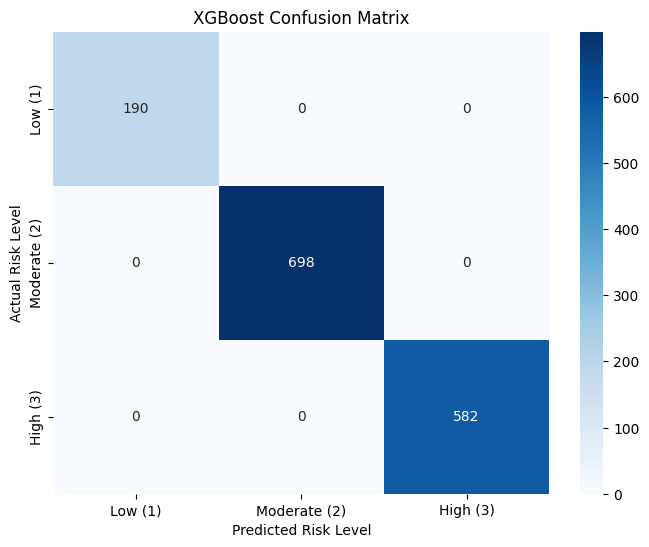

In [ ]:
from xgboost import XGBClassifier

# Create the XGBoost model pipeline
# Note: XGBoost usually expects integer labels starting from 0 for multi-class classification
# Our Risk_Score is 1, 2, 3, so we need to adjust y_train and y_test if not already done, or ensure XGBoost handles it.
# Let's adjust to 0, 1, 2 for 'Low', 'Moderate', 'High' to be safe.
# If y is already mapped to 0, 1, 2 (e.g., by subtracting 1), this step is not needed.
# Assuming y is 1,2,3 for now, will handle if error occurs.

xgb_model = Pipeline(steps=[('preprocessor', preprocessor),
                           ('classifier', XGBClassifier(objective='multi:softmax', num_class=3, random_state=42, use_label_encoder=False, eval_metric='mlogloss'))])

# Train the model
xgb_model.fit(X_train, y_train - 1) # Adjust target labels to be 0-indexed

# Make predictions on the test set
# Predictions from multi:softmax will be 0-indexed, so we add 1 back for consistency with original labels
y_pred_xgb = xgb_model.predict(X_test) + 1

# Evaluate the model
accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
report_xgb = classification_report(y_test, y_pred_xgb)
conf_mat_xgb = confusion_matrix(y_test, y_pred_xgb)

print(f"\nXGBoost Model Accuracy: {accuracy_xgb:.4f}")
print("\nXGBoost Classification Report:")
print(report_xgb)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_mat_xgb, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Low (1)', 'Moderate (2)', 'High (3)'],
            yticklabels=['Low (1)', 'Moderate (2)', 'High (3)'])
plt.xlabel('Predicted Risk Level')
plt.ylabel('Actual Risk Level')
plt.title('XGBoost Confusion Matrix')
plt.show()

## LightGBM Classifier

**When to use it:** LightGBM (Light Gradient Boosting Machine) is another gradient boosting framework that uses tree-based learning algorithms. It's designed for efficiency and can handle large datasets with high dimensionality. It often outperforms XGBoost in terms of training speed and memory usage while maintaining comparable accuracy. It's a good choice when computational resources are a concern or when working with very large datasets.

We'll use LightGBM for `Risk_Level` classification as well.

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000728 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 870
[LightGBM] [Info] Number of data points in the train set: 5880, number of used features: 66
[LightGBM] [Info] Start training from score -2.043365
[LightGBM] [Info] Start training from score -0.745515
[LightGBM] [Info] Start training from score -0.926547
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No fu

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



LightGBM Model Accuracy: 1.0000

LightGBM Classification Report:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00       190
           2       1.00      1.00      1.00       698
           3       1.00      1.00      1.00       582

    accuracy                           1.00      1470
   macro avg       1.00      1.00      1.00      1470
weighted avg       1.00      1.00      1.00      1470



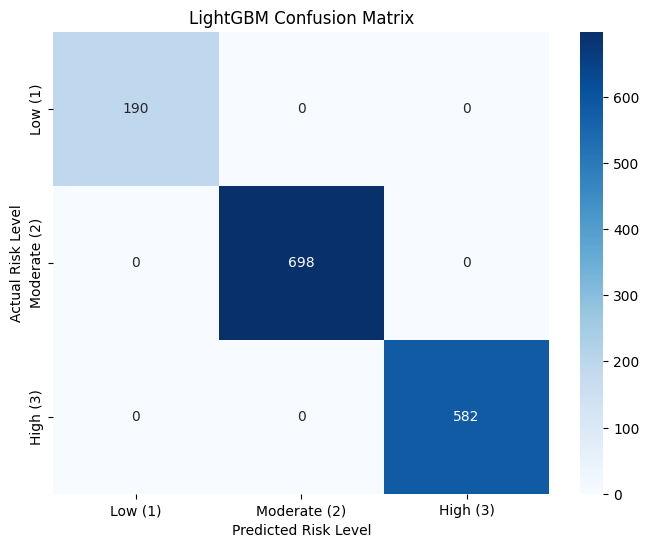

In [ ]:
from lightgbm import LGBMClassifier

# Create the LightGBM model pipeline
lgbm_model = Pipeline(steps=[('preprocessor', preprocessor),
                            ('classifier', LGBMClassifier(objective='multiclass', num_class=3, random_state=42))])

# Train the model
lgbm_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_lgbm = lgbm_model.predict(X_test)

# Evaluate the model
accuracy_lgbm = accuracy_score(y_test, y_pred_lgbm)
report_lgbm = classification_report(y_test, y_pred_lgbm)
conf_mat_lgbm = confusion_matrix(y_test, y_pred_lgbm)

print(f"\nLightGBM Model Accuracy: {accuracy_lgbm:.4f}")
print("\nLightGBM Classification Report:")
print(report_lgbm)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_mat_lgbm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Low (1)', 'Moderate (2)', 'High (3)'],
            yticklabels=['Low (1)', 'Moderate (2)', 'High (3)'])
plt.xlabel('Predicted Risk Level')
plt.ylabel('Actual Risk Level')
plt.title('LightGBM Confusion Matrix')
plt.show()

## K-Means Clustering

**When to use it:** K-Means is an unsupervised learning algorithm, which means it works with unlabeled data. Its primary goal is to discover underlying structures or groupings (clusters) within the data. It's useful for tasks like customer segmentation, document categorization, or anomaly detection. Unlike the previous models, K-Means does not predict a target variable; instead, it groups similar data points together based on their feature values.

In our context, we could use K-Means to see if there are natural clusters of `MEASURING_POINT`s based on their `LATITUDE`, `LONGITUDE`, `AVG_NOISE_LVL`, and `Duration_hours` that might correspond to different risk profiles, even without using the `Risk_Level` labels initially. This can help reveal inherent patterns in the data.

**Note**: For K-Means, features should be scaled. We will use the numerical features already scaled by our preprocessor.

Cluster distribution:
Cluster
2    2652
0    2591
1    2107
Name: count, dtype: int64


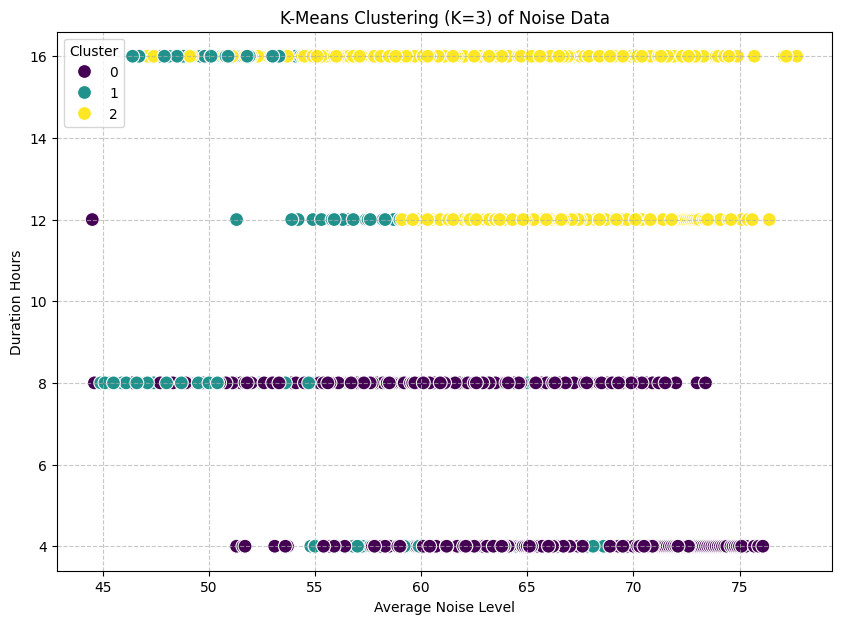


Mean feature values per cluster:
          LATITUDE  LONGITUDE  Duration_hours  AVG_NOISE_LVL
Cluster                                                     
0        51.150151  18.295444        6.389811      62.477846
1        52.882113  21.117234       10.213574      58.444850
2        51.274090  18.522530       14.491704      66.275641


In [ ]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# For clustering, we usually don't use the target variable 'y'
# We'll use the preprocessor to scale the relevant numerical features

# Select features relevant for clustering
clustering_features = df[numerical_features]

# Scale the features using StandardScaler (re-initializing for simplicity, or use a fitted scaler)
scaler = StandardScaler()
scaled_clustering_features = scaler.fit_transform(clustering_features)

# Determine the optimal number of clusters (e.g., using the Elbow Method)
# For demonstration, let's try K=3, as we have 3 risk levels, though K-Means doesn't 'know' this.

k = 3  # Number of clusters
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10) # n_init is set to 'auto' or int in newer versions
clusters = kmeans.fit_predict(scaled_clustering_features)

# Add cluster labels to the original DataFrame for analysis
df['Cluster'] = clusters

print("Cluster distribution:")
print(df['Cluster'].value_counts())

# Visualize the clusters (e.g., using a scatter plot of two important features)
plt.figure(figsize=(10, 7))
sns.scatterplot(x='AVG_NOISE_LVL', y='Duration_hours', hue='Cluster', data=df, palette='viridis', s=100)
plt.title(f'K-Means Clustering (K={k}) of Noise Data')
plt.xlabel('Average Noise Level')
plt.ylabel('Duration Hours')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

# You can further analyze clusters by looking at the mean of features within each cluster
print("\nMean feature values per cluster:")
print(df.groupby('Cluster')[numerical_features].mean())

In [ ]:
first_sample_probabilities = y_pred_proba[0]
sum_probabilities = np.sum(first_sample_probabilities)
print(f"Sum of probabilities for the first sample: {sum_probabilities}")

Sum of probabilities for the first sample: 1.0


### Is the Logistic Regression Model "Worthy"?

Based on the evaluation metrics above, we can determine the 'worthiness' of this logistic regression model for predicting `Risk_Level`:

*   **Accuracy**: The overall accuracy score indicates the proportion of correctly predicted risk levels. A higher accuracy suggests a more reliable model.
*   **Precision, Recall, F1-score**: These metrics from the classification report provide a deeper insight into the model's performance for each `Risk_Level` class:
    *   **Precision**: How many of the predicted positives were actually positive?
    *   **Recall**: How many of the actual positives were correctly identified?
    *   **F1-score**: The harmonic mean of precision and recall, offering a balance between the two.
*   **Confusion Matrix**: This visualizes where the model is making correct predictions and where it's making errors. You can see how many instances of 'Low' risk were predicted as 'Moderate' or 'High', and vice-versa.

**To determine if it's 'worthy' depends on your specific goals and acceptable error rates:**

*   **If high accuracy across all classes is crucial**, you'll examine if precision, recall, and F1-scores are consistently high for 'Low', 'Moderate', and 'High' risk levels.
*   **If misclassifying 'High' risk as 'Low' is particularly costly**, you'd pay close attention to the recall of the 'High' class and the number of 'High' actuals predicted as 'Low' in the confusion matrix.

**Logistic regression is a strong candidate when you need:**

1.  **Interpretability**: The coefficients of the logistic regression model (after inverse-transforming scaled features and handling one-hot encoding) can provide insights into how each feature influences the log-odds of a particular risk level.
2.  **Probabilistic Outputs**: It provides probabilities for each class, which can be useful for decision-making (e.g., how confident is the model that a town has 'High' risk).
3.  **Baseline Model**: It often serves as an excellent baseline model due to its simplicity and interpretability, against which more complex models can be compared.

**Potential Limitations to Consider:**

*   **Linearity Assumption**: Logistic regression assumes a linear relationship between the independent variables and the log-odds of the dependent variable. If the true relationship is highly non-linear, more complex models might perform better.
*   **Multi-Collinearity**: High correlation between predictor variables can make the model coefficients unstable.
*   **High Cardinality of 'TOWN'**: One-hot encoding `TOWN` creates many new features (one for each town), which can make the model sparse and potentially less efficient, although for this dataset it's manageable. If there were thousands of towns, other encoding methods might be preferred.

In conclusion, the model's worthiness is subjective to your business context. The evaluation metrics provide the empirical evidence to make that decision. If the model's performance meets your project's requirements, then it is indeed worthy. If not, it serves as a valuable starting point for further model refinement or exploration of other algorithms.

In [ ]:
# Save the DataFrame with imputed (and thus geographically labeled) 'TOWN' data
df.to_csv('Noise_Data_Imputed_and_Labeled.csv', index=False)
print("DataFrame with geographically labeled towns saved to 'Noise_Data_Imputed_and_Labeled.csv'")

DataFrame with geographically labeled towns saved to 'Noise_Data_Imputed_and_Labeled.csv'


In [ ]:
display(df[['LATITUDE', 'LONGITUDE', 'TOWN']].head())

,LATITUDE,LONGITUDE,TOWN
0,51.2558,15.5806,Boleslawiec
1,51.2558,15.5806,Boleslawiec
2,51.2534,15.5659,Boleslawiec
3,51.2534,15.5659,Boleslawiec
4,51.2649,15.5549,Boleslawiec
